# Abalone: exploring the training data
Rémi Barbier

Source: [course dataset on Kaggle](https://www.kaggle.com/datasets/rodolfomendes/abalone-dataset). We predict shell rings from sex and seven measurements. Approximate age is rings plus 1.5 years. The plots below use the training partition; validation and test rows are kept aside.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
source = ROOT / "data/abalone.csv"
raw = pd.read_csv(source)
data = raw.rename(columns=lambda name: name.lower().replace(" ", "_"))
numeric = ["length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight"]
valid = data[numeric].gt(0).all(axis=1) & data.sex.isin(["M", "F", "I"])
valid &= data.rings.gt(0) & data[numeric + ["rings"]].notna().all(axis=1)
clean = data.loc[valid].copy()
development, test = train_test_split(clean, test_size=0.2, random_state=42)
train, validation = train_test_split(development, test_size=0.25, random_state=42)
features = ["sex"] + numeric


## Data quality and split
Nonpositive physical measurements are excluded consistently in training and at the API boundary. No upper outlier cutoff is chosen from the test results.

In [2]:
pd.DataFrame({"count": {
    "source rows": len(raw), "missing cells": int(raw.isna().sum().sum()),
    "duplicate rows": int(raw.duplicated().sum()), "excluded invalid rows": int((~valid).sum()),
    "training rows": len(train), "validation rows": len(validation), "test rows": len(test)
}})

,count
duplicate rows,0
excluded invalid rows,2
missing cells,0
source rows,4177
test rows,835
training rows,2505
validation rows,835


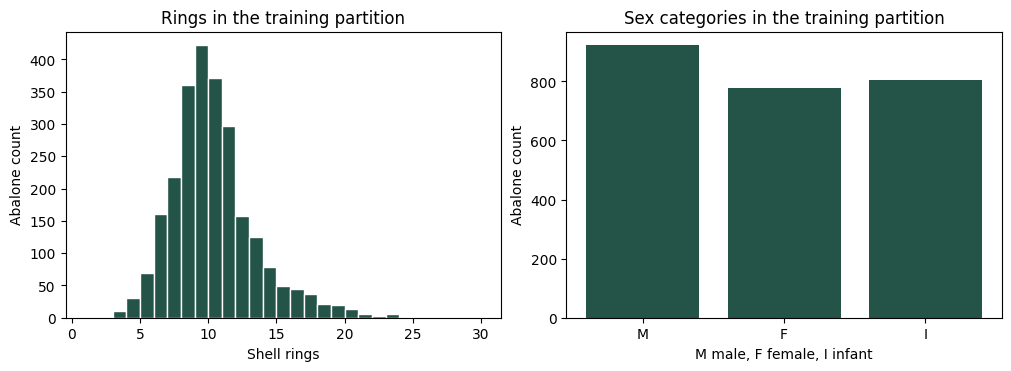

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
axes[0].hist(train.rings, bins=range(1, 31), color="#235447", edgecolor="white")
axes[0].set(title="Rings in the training partition", xlabel="Shell rings", ylabel="Abalone count")
counts = train.sex.value_counts().reindex(["M", "F", "I"])
axes[1].bar(counts.index, counts.values, color="#235447")
axes[1].set(title="Sex categories in the training partition", xlabel="M male, F female, I infant", ylabel="Abalone count")
plt.show()

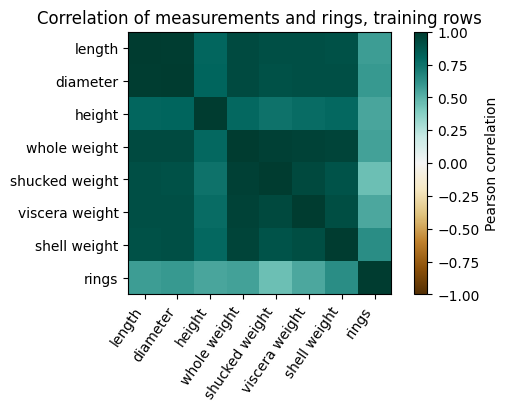

In [4]:
fig, ax = plt.subplots(figsize=(5.8, 4), constrained_layout=True)
correlation = train[numeric + ["rings"]].corr()
image = ax.imshow(correlation, cmap="BrBG", vmin=-1, vmax=1)
labels = [name.replace("_", " ") for name in correlation.columns]
ax.set_xticks(range(len(labels)), labels, rotation=55, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Correlation of measurements and rings, training rows")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.show()

## What this changes for modelling
The target is concentrated around the middle of its range, so a mean-prediction baseline is useful. The size and weight variables overlap strongly. We compare linear regression with a small random forest to capture nonlinear relationships. Sex is encoded as a category, including the infant category. Rings and derived age are never inputs. The two zero-height rows are excluded. The dataset is small and historical; the random holdout assesses this dataset, not transfer to a different population.